In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, ConfusionMatrixDisplay)

print('✅ All Libraries Imported Successfully!')

✅ All Libraries Imported Successfully!


In [2]:
np.random.seed(42)
n = 500  # 500 students

# Features generate karo
attendance  = np.random.uniform(40, 100, n)
study_hours = np.random.uniform(1, 10, n)
prev_marks  = np.random.uniform(30, 100, n)
test_scores = np.random.uniform(30, 100, n)

# Weighted score calculate karo
avg_score = (attendance   * 0.20 +
             prev_marks   * 0.40 +
             test_scores  * 0.30 +
             study_hours  * 5 * 0.10)

# Label assign karo
def assign_label(score):
    if score >= 70:
        return 'Good'
    elif score >= 50:
        return 'Average'
    else:
        return 'Low'

performance = [assign_label(s) for s in avg_score]

# DataFrame banao
df = pd.DataFrame({
    'attendance_pct'      : attendance.round(1),
    'study_hours_per_day' : study_hours.round(1),
    'previous_marks'      : prev_marks.round(1),
    'test_scores'         : test_scores.round(1),
    'performance'         : performance
})

df.to_csv('students.csv', index=False)

print('✅ Dataset Ready!')
print(f'Total Students: {len(df)}')
print('\nPerformance Distribution:')
print(df['performance'].value_counts())
print('\nFirst 5 rows:')
df.head()

✅ Dataset Ready!
Total Students: 500

Performance Distribution:
performance
Average    300
Good       129
Low         71
Name: count, dtype: int64

First 5 rows:


,attendance_pct,study_hours_per_day,previous_marks,test_scores,performance
0,62.5,7.3,43.0,66.3,Average
1,97.0,5.8,67.9,63.5,Average
2,83.9,3.8,91.1,31.8,Average
3,75.9,8.3,81.3,53.9,Average
4,49.4,7.2,86.5,56.6,Average


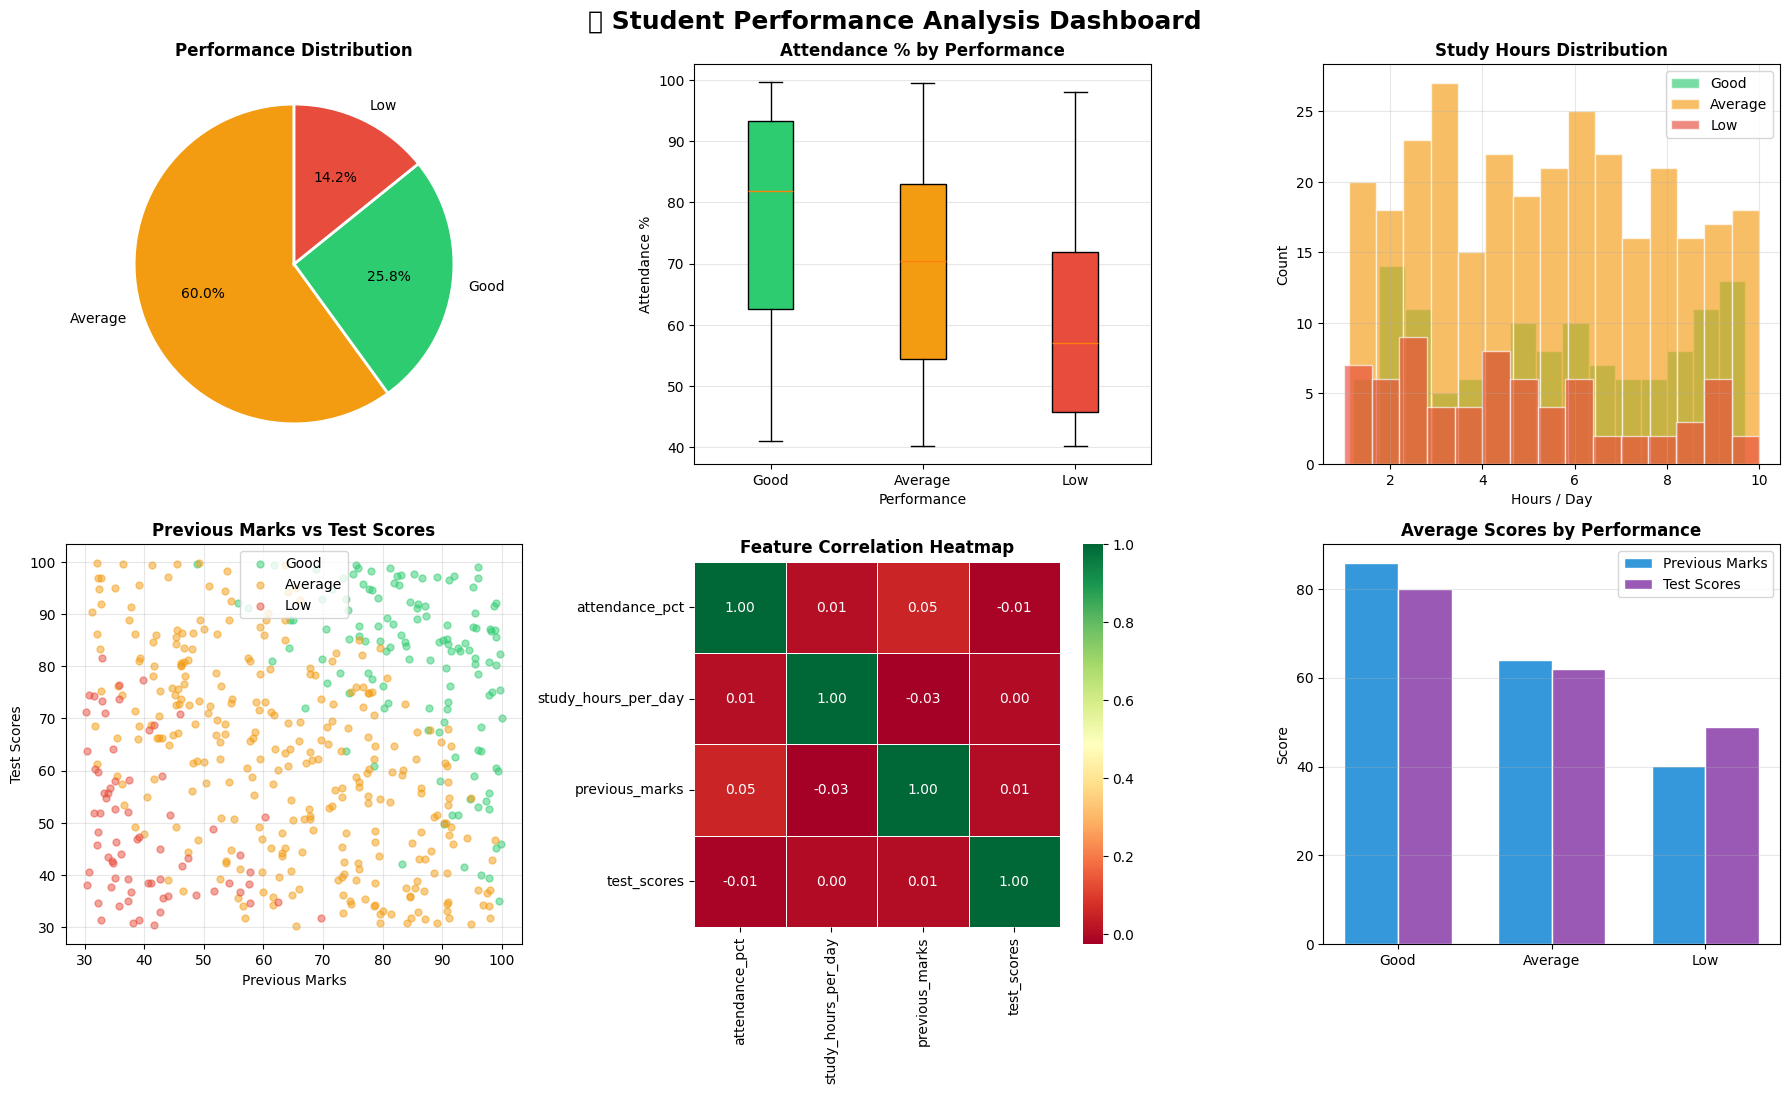

✅ Visualizations Ready!


In [3]:
colors = {'Good': '#2ecc71', 'Average': '#f39c12', 'Low': '#e74c3c'}
order  = ['Good', 'Average', 'Low']

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('🎓 Student Performance Analysis Dashboard',
             fontsize=18, fontweight='bold')

# 1. Pie Chart
ax = axes[0, 0]
counts = df['performance'].value_counts()
ax.pie(counts, labels=counts.index, autopct='%1.1f%%',
       colors=[colors[k] for k in counts.index],
       startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.set_title('Performance Distribution', fontweight='bold')

# 2. Box Plot
ax = axes[0, 1]
data_box = [df[df['performance'] == p]['attendance_pct'].values for p in order]
bp = ax.boxplot(data_box, labels=order, patch_artist=True)
for patch, perf in zip(bp['boxes'], order):
    patch.set_facecolor(colors[perf])
ax.set_title('Attendance % by Performance', fontweight='bold')
ax.set_xlabel('Performance')
ax.set_ylabel('Attendance %')
ax.grid(axis='y', alpha=0.3)

# 3. Histogram
ax = axes[0, 2]
for perf in order:
    subset = df[df['performance'] == perf]['study_hours_per_day']
    ax.hist(subset, alpha=0.65, label=perf, color=colors[perf],
            bins=15, edgecolor='white')
ax.set_title('Study Hours Distribution', fontweight='bold')
ax.set_xlabel('Hours / Day')
ax.set_ylabel('Count')
ax.legend()
ax.grid(alpha=0.3)

# 4. Scatter Plot
ax = axes[1, 0]
for perf in order:
    sub = df[df['performance'] == perf]
    ax.scatter(sub['previous_marks'], sub['test_scores'],
               alpha=0.5, label=perf, color=colors[perf], s=25)
ax.set_title('Previous Marks vs Test Scores', fontweight='bold')
ax.set_xlabel('Previous Marks')
ax.set_ylabel('Test Scores')
ax.legend()
ax.grid(alpha=0.3)

# 5. Heatmap
ax = axes[1, 1]
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            ax=ax, linewidths=0.5, square=True)
ax.set_title('Feature Correlation Heatmap', fontweight='bold')

# 6. Bar Chart
ax = axes[1, 2]
avg = df.groupby('performance')[['previous_marks', 'test_scores']].mean().loc[order]
x = np.arange(len(order))
w = 0.35
ax.bar(x - w/2, avg['previous_marks'], w, label='Previous Marks',
       color='#3498db', edgecolor='white')
ax.bar(x + w/2, avg['test_scores'], w, label='Test Scores',
       color='#9b59b6', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_title('Average Scores by Performance', fontweight='bold')
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('performance_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Visualizations Ready!')

In [4]:
# Features & Target
X = df[['attendance_pct', 'study_hours_per_day',
        'previous_marks', 'test_scores']]
y = df['performance']

# Label Encoding
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print('Label Mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

# Feature Scaling
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded,
    test_size=0.2, random_state=42, stratify=y_encoded
)

print(f'\nTraining Samples : {len(X_train)}')
print(f'Testing  Samples : {len(X_test)}')

# Random Forest Model Train
model = RandomForestClassifier(
    n_estimators = 100,
    max_depth    = 10,
    random_state = 42
)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f'\n🎯 Model Accuracy: {acc*100:.2f}%')

# Cross Validation
cv_scores = cross_val_score(model, X_scaled, y_encoded, cv=5)
print(f'📊 5-Fold CV Accuracy: {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%')

print('\n✅ Model Trained Successfully!')

Label Mapping: {'Average': np.int64(0), 'Good': np.int64(1), 'Low': np.int64(2)}

Training Samples : 400
Testing  Samples : 100

🎯 Model Accuracy: 85.00%
📊 5-Fold CV Accuracy: 89.80% ± 3.43%

✅ Model Trained Successfully!


       PERFORMANCE ANALYSIS REPORT
              precision    recall  f1-score   support

     Average       0.83      0.95      0.88        60
        Good       0.91      0.81      0.86        26
         Low       0.88      0.50      0.64        14

    accuracy                           0.85       100
   macro avg       0.87      0.75      0.79       100
weighted avg       0.86      0.85      0.84       100



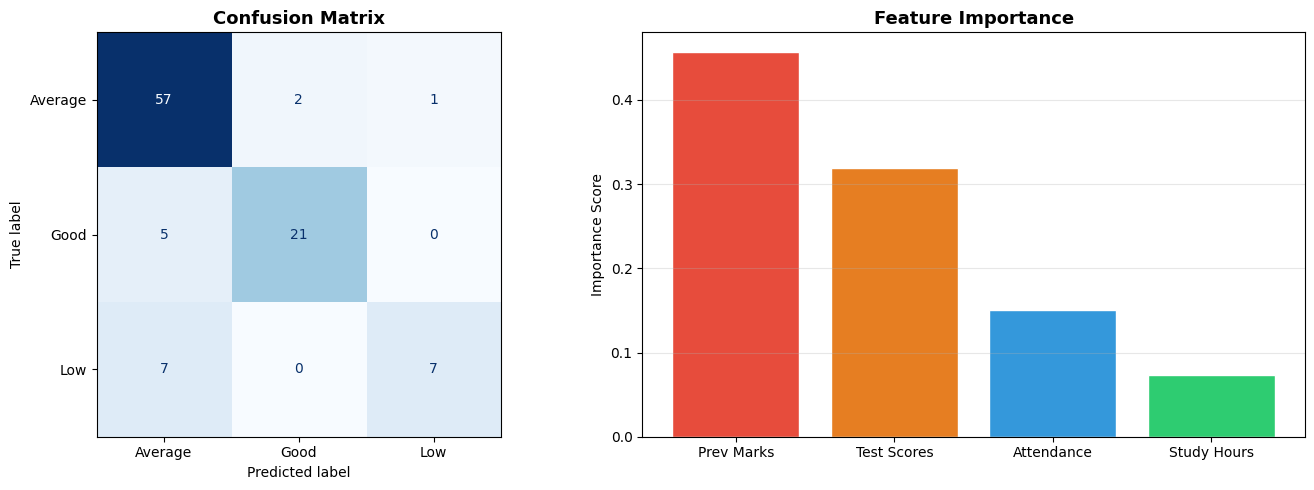

✅ Analysis Complete!


In [5]:
print('=' * 55)
print('       PERFORMANCE ANALYSIS REPORT')
print('=' * 55)
print(classification_report(y_test, y_pred,
                             target_names=le.classes_))

# Confusion Matrix + Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix', fontweight='bold', fontsize=13)

# Feature Importance
importances = model.feature_importances_
feat_names  = ['Attendance', 'Study Hours', 'Prev Marks', 'Test Scores']
idx         = np.argsort(importances)[::-1]

axes[1].bar(range(4), importances[idx],
            color=['#e74c3c','#e67e22','#3498db','#2ecc71'],
            edgecolor='white')
axes[1].set_xticks(range(4))
axes[1].set_xticklabels([feat_names[i] for i in idx])
axes[1].set_title('Feature Importance', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Importance Score')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Analysis Complete!')

In [6]:
def predict_student(attendance, study_hours, prev_marks, test_score):
    features        = np.array([[attendance, study_hours, prev_marks, test_score]])
    features_scaled = scaler.transform(features)

    pred        = model.predict(features_scaled)[0]
    proba       = model.predict_proba(features_scaled)[0]
    performance = le.inverse_transform([pred])[0]

    estimated_score = round(test_score * 0.6 + prev_marks * 0.4, 2)

    emoji  = {'Good': '🟢', 'Average': '🟡', 'Low': '🔴'}
    advice = {
        'Good'   : '✅ Excellent! Keep it up.',
        'Average': '📚 Improve study hours & attendance.',
        'Low'    : '⚠️ Serious attention required!'
    }

    print('=' * 50)
    print('      🎓 STUDENT PERFORMANCE REPORT')
    print('=' * 50)
    print(f'  Attendance       : {attendance}%')
    print(f'  Study Hours/Day  : {study_hours} hrs')
    print(f'  Previous Marks   : {prev_marks}/100')
    print(f'  Test Score       : {test_score}/100')
    print('-' * 50)
    print(f'  Predicted Perf.  : {emoji[performance]} {performance}')
    print(f'  Estimated Score  : {estimated_score}/100')
    print(f'  Confidence       : {max(proba)*100:.1f}%')
    print('-' * 50)
    print(f'  Advice           : {advice[performance]}')
    print('=' * 50)

# --- Test 1: Good Student ---
predict_student(90, 7, 85, 88)

      🎓 STUDENT PERFORMANCE REPORT
  Attendance       : 90%
  Study Hours/Day  : 7 hrs
  Previous Marks   : 85/100
  Test Score       : 88/100
--------------------------------------------------
  Predicted Perf.  : 🟢 Good
  Estimated Score  : 86.8/100
  Confidence       : 100.0%
--------------------------------------------------
  Advice           : ✅ Excellent! Keep it up.


In [8]:
def predict_student(attendance, study_hours, prev_marks, test_score):
    features        = np.array([[attendance, study_hours, prev_marks, test_score]])
    features_scaled = scaler.transform(features)

    pred        = model.predict(features_scaled)[0]
    proba       = model.predict_proba(features_scaled)[0]
    performance = le.inverse_transform([pred])[0]

    estimated_score = round(test_score * 0.6 + prev_marks * 0.4, 2)

    emoji  = {'Good': '🟢', 'Average': '🟡', 'Low': '🔴'}
    advice = {
        'Good'   : '✅ Excellent! Keep it up.',
        'Average': '📚 Improve study hours & attendance.',
        'Low'    : '⚠️ Serious attention required!'
    }

    print('=' * 50)
    print('      🎓 STUDENT PERFORMANCE REPORT')
    print('=' * 50)
    print(f'  Attendance       : {attendance}%')
    print(f'  Study Hours/Day  : {study_hours} hrs')
    print(f'  Previous Marks   : {prev_marks}/100')
    print(f'  Test Score       : {test_score}/100')
    print('-' * 50)
    print(f'  Predicted Perf.  : {emoji[performance]} {performance}')
    print(f'  Estimated Score  : {estimated_score}/100')
    print(f'  Confidence       : {max(proba)*100:.1f}%')
    print('-' * 50)
    print(f'  Advice           : {advice[performance]}')
    print('=' * 50)

# --- Test 1: Good Student ---
predict_student(60, 2, 40, 50)

      🎓 STUDENT PERFORMANCE REPORT
  Attendance       : 60%
  Study Hours/Day  : 2 hrs
  Previous Marks   : 40/100
  Test Score       : 50/100
--------------------------------------------------
  Predicted Perf.  : 🔴 Low
  Estimated Score  : 46.0/100
  Confidence       : 74.1%
--------------------------------------------------
  Advice           : ⚠️ Serious attention required!
